# code_008 · Geometry, projections and decompositions

**Book:** Chapter 2, section 2.2. **Scope:** a mathematics laboratory, with exact toy models and generated data. This is not a field-validation study or an exhaustive estimator-constructor lab. All imports, inputs and helpers are contained here.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt), then restart and run all cells. The reference environment is CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1 and Matplotlib 3.11.0, macOS ARM64 CPU. No data downloads, API keys, GPU or project imports are needed. Allow a minute for execution and 30–60 minutes for predictions and exercises. Actual runtime appears at the end and in [execution evidence](../CHAPTER_02_EXECUTION.md).

Read each prediction before revealing output. Controls here are coordinate choices, numerical-method settings and stated system/data assumptions; they are not collectively model hyperparameters. These constructed mechanism checks do not need a supervised train/test split. A later fitted predictive pipeline must learn scales and representations on training data only. See the [concept-to-code guide](../CHAPTER_02_GUIDE.md) and [stable code directory](../CODE_EXAMPLES.md#code_008).


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter(); SEED=202
rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine())
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64


<a id="scales"></a>
## Geometry begins with a scale choice

Distance is measured in the supplied coordinates. Three observations below contain length in m and temperature in deg C; their unscaled distance is not a physical norm. Reference scales produce dimensionless coordinates and explicitly choose relative importance. They are fixed teaching choices, not fitted evidence of task relevance.

**Predict:** does converting length to mm change the nearest neighbor under raw numeric Euclidean distance? Would converting the reference scale consistently change the normalized distance?


In [2]:
observations=np.array([[3.,20.],[3.1,25.],[4.,20.1]])
raw=np.linalg.norm(observations[1:]-observations[0],axis=1)
mm=observations.copy();mm[:,0]*=1000
raw_mm=np.linalg.norm(mm[1:]-mm[0],axis=1)
scales=np.array([1.,10.]);normed=np.linalg.norm((observations[1:]-observations[0])/scales,axis=1)
assert np.argmin(raw)!=np.argmin(raw_mm)
assert np.allclose(normed,np.linalg.norm((mm[1:]-mm[0])/(scales*[1000,1]),axis=1))
print('Raw distances:',raw,'after m to mm:',raw_mm,'dimensionless:',normed)


Raw distances: [5.0009999  1.00498756] after m to mm: [ 100.12492197 1000.000005  ] dimensionless: [0.50990195 1.00005   ]


<a id="projection-svd"></a>
## Projection and reconstruction

Generate two dimensionless corrected sensor channels from a strong shared direction and weaker orthogonal variation. Centering removes the column means, then reduced SVD gives the principal directions. Scores multiply on the right because observations are rows. The discarded-energy identity is an exact finite-matrix statement up to arithmetic error.

**Predict:** what are the reconstruction errors for zero and two components? Why should a sign flip of a direction leave its projection unchanged? The scatter plot's dashed segments show information removed by retaining only one coordinate.


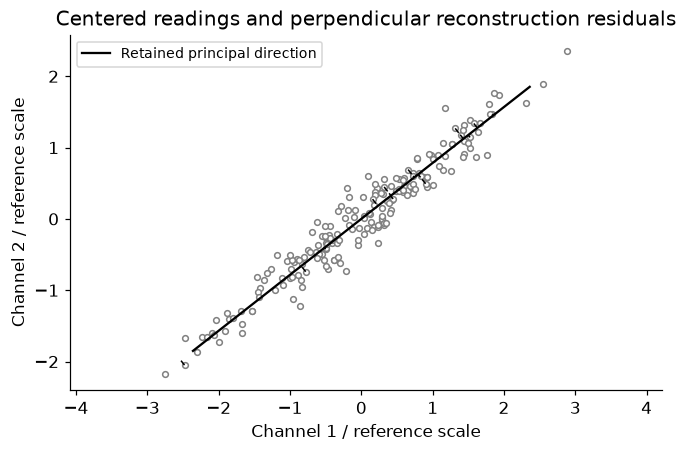

Squared reconstruction errors: [371.0581433524967, 5.509044359109652, 4.627294955797227e-30] retained fraction: 0.9851531506374293


In [3]:
v=np.array([1.,.8]);v/=np.linalg.norm(v);weak=np.array([-v[1],v[0]])
X=rng.normal(size=(200,1))*v*1.3+rng.normal(size=(200,1))*weak*.16
mu=X.mean(0);Xc=X-mu;U,s,Vt=np.linalg.svd(Xc,full_matrices=False)
errors=[]
for rank in range(3):
 Vr=Vt[:rank].T;recon=(Xc@Vr)@Vr.T
 error=float(np.linalg.norm(Xc-recon,'fro')**2);errors.append(error)
 assert np.allclose(error,np.sum(s[rank:]**2),atol=1e-10)
V=Vt[:1].T;recon=Xc@V@V.T;residual=Xc-recon
assert np.allclose(residual@V,0,atol=1e-12)
assert np.allclose(Xc@(-V)@(-V).T,recon)
cov=Xc.T@Xc/(len(X)-1);ev=np.linalg.eigvalsh(cov)[::-1]
assert np.allclose(ev,s**2/(len(X)-1))
fig,ax=plt.subplots(figsize=(6,4));ax.scatter(*Xc.T,s=14,facecolors='white',edgecolors='.5')
for i in range(0,200,15):ax.plot([Xc[i,0],recon[i,0]],[Xc[i,1],recon[i,1]],'k--',lw=1)
line=np.outer(np.array([-3.,3.]),V[:,0]);ax.plot(*line.T,'k-',label='Retained principal direction')
ax.set(xlabel='Channel 1 / reference scale',ylabel='Channel 2 / reference scale',title='Centered readings and perpendicular reconstruction residuals');ax.axis('equal');ax.legend(fontsize=9);plt.show()
print('Squared reconstruction errors:',errors,'retained fraction:',s[0]**2/np.sum(s**2))
RESULTS['reconstruction_squared_errors']=errors;RESULTS['retained_fraction']=float(s[0]**2/np.sum(s**2))


<a id="weak-signal"></a>
## High retained variance can remove an important signal

Use the *learned* low-variance direction to create a controlled perturbation of fixed magnitude. A one-component projection removes it exactly; a full reconstruction keeps it. This proves information loss, not that real defects occupy the weak direction or that all residuals indicate damage. PCA labels no defect classes. A future predictive assessment must fit PCA only on training observations and assess usefulness on held-out entities/times.

**Predict:** how would the conclusion change if the injected signal lay along the retained direction? What evidence would justify choosing a rank for a real inspection task?


In [4]:
shift=.2*Vt[1];perturbed=Xc+shift
compressed_delta=(perturbed@V@V.T)-(Xc@V@V.T)
assert np.allclose(compressed_delta,0,atol=1e-12)
assert np.isclose(np.linalg.norm(shift),.2)
print('Input signal magnitude:',np.linalg.norm(shift),'retained change max:',np.max(np.abs(compressed_delta)))
RESULTS['injected_signal_norm']=float(np.linalg.norm(shift));RESULTS['retained_signal_max_abs']=float(np.max(np.abs(compressed_delta)))


Input signal magnitude: 0.2 retained change max: 4.440892098500626e-16


<a id="conditioning"></a>
## Nearly dependent columns

`A=[x,x+epsilon*z]` has two increasingly similar columns. For every epsilon, compare the exact baseline with a fixed perturbation of the right-hand side along `z`. The algebra implies a coefficient change proportional to `1/epsilon`, while the change in fitted response has fixed norm. This keeps the perturbation's cause separate from rank tolerance. Coefficients and predictions have different sensitivity.

**Predict:** what happens to the two coefficients as epsilon is divided by ten? Is a tiny residual evidence that those coefficients are well identified?


,column_separation,condition_number,coefficient_change,prediction_change
0,1.00000,2.618034,0.000141,0.0001
1,0.10000,20.050125,0.001414,0.0001
2,0.01000,200.005000,0.014142,0.0001
3,0.00100,2000.000500,0.141421,0.0001
4,0.00010,20000.000050,1.414214,0.0001
5,0.00001,200000.000004,14.142136,0.0001


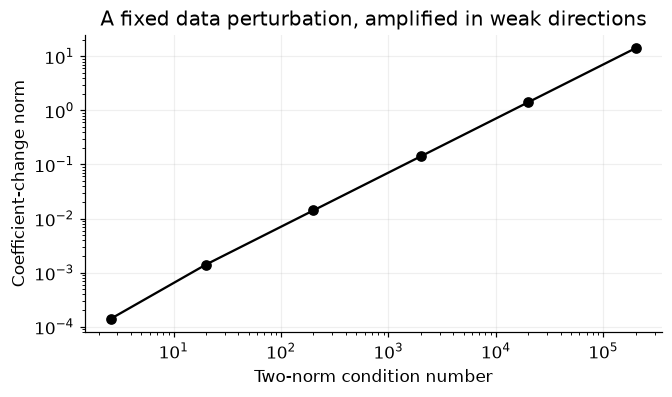

In [5]:
x=np.linspace(-1,1,100);x/=np.linalg.norm(x)
z=np.cos(np.arange(100));z-=x*(x@z);z/=np.linalg.norm(z)
rows=[]
for eps in [1.,.1,.01,.001,1e-4,1e-5]:
 A=np.column_stack([x,x+eps*z]);b=A@np.array([1.,1.]);db=1e-4*z
 beta=np.linalg.lstsq(A,b,rcond=None)[0];changed=np.linalg.lstsq(A,b+db,rcond=None)[0]
 change=np.linalg.norm(changed-beta);pred_change=np.linalg.norm(A@(changed-beta))
 assert np.isclose(change,np.sqrt(2)*1e-4/eps,rtol=1e-5)
 assert np.isclose(pred_change,1e-4,rtol=1e-5)
 rows.append([eps,np.linalg.cond(A),change,pred_change])
table=pd.DataFrame(rows,columns=['column_separation','condition_number','coefficient_change','prediction_change']);display(table)
fig,ax=plt.subplots(figsize=(6,3.5));ax.loglog(table.condition_number,table.coefficient_change,'ko-');ax.set(xlabel='Two-norm condition number',ylabel='Coefficient-change norm',title='A fixed data perturbation, amplified in weak directions');ax.grid(alpha=.2);plt.show()
RESULTS['largest_condition_number']=float(table.condition_number.iloc[-1]);RESULTS['largest_coefficient_change']=float(table.coefficient_change.iloc[-1])


<a id="exercises"></a>
## Exercises and hints

1. Change the reference scales, leaving physical observations fixed. Explain the changed nearest-neighbor choice.
2. Rescale one sensor channel by 100. Fit PCA again and compare reconstructed physical-unit error after converting back.
3. Retain both directions, or inject a strong-direction signal. State exactly which information-loss claim changes.
4. Verify that a sign flip changes scores but not reconstructed points. Compare covariance eigenvalues with squared singular values.
5. Add a third independent measurement to the nearly dependent system. Decide whether it adds information about the weak coefficient combination.

**Hints:** scales define geometry; an extra copy of the same channel adds little independent information. A perfectly constant matrix has zero total centered variance, so a retained-variance *fraction* needs an explicit zero-total convention. Tied singular values make axes nonunique; compare projectors instead of signs.

**Troubleshooting:** specify `full_matrices=False` for the reduced shapes used here, and restore the training mean after reconstruction. Official [SVD documentation](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html) defines the routine; the retained-energy and sensitivity calculations above are explicit mathematical checks.


In [6]:
summary={'example_id':'code_008','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU',
'concepts_demonstrated':['norms and reference scales', 'orthogonal projection', 'SVD and PCA reconstruction', 'discarded low-variance signal', 'conditioning and coefficient sensitivity'],'results':RESULTS,
'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["norms and reference scales", "orthogonal projection", "SVD and PCA reconstruction", "discarded low-variance signal", "conditioning and coefficient sensitivity"], "elapsed_seconds": 0.274, "example_id": "code_008", "hardware": "Darwin arm64 CPU", "results": {"injected_signal_norm": 0.2, "largest_coefficient_change": 14.142135623687942, "largest_condition_number": 200000.00000430975, "reconstruction_squared_errors": [371.0581433524967, 5.509044359109652, 4.627294955797227e-30], "retained_fraction": 0.9851531506374293, "retained_signal_max_abs": 4.440892098500626e-16}, "seed": 202, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
